## 1. Importer les bibliothèques

# 01 — Data Understanding & Exploratory Data Analysis
## Projet : AutoML & MLOps Platform — Telco Customer Churn

**Objectif :** comprendre le dataset avant de construire les modèles de Machine Learning.

Ce notebook permet de :
1. Charger et examiner les données.
2. Comprendre les variables et la cible `Churn`.
3. Vérifier les valeurs manquantes, doublons et types incorrects.
4. Explorer les distributions et relations avec `Churn`.
5. Préparer une copie nettoyée du dataset dans `data/processed/`.

> Important : le fichier original dans `data/raw/` n'est jamais modifié.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


## 2. Définir les chemins et charger le dataset
Cette cellule fonctionne si le notebook est enregistré dans `notebooks/` et si Jupyter est lancé depuis la racine du projet.

In [8]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", PROJECT_ROOT)
print("Fichier dataset :", DATA_PATH)
print("Fichier trouvé :", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset introuvable : {DATA_PATH}\n"
        "Vérifie que Telco-Customer-Churn.csv est dans data/raw/."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset chargé avec succès !")

Racine du projet : C:\Users\Octinz\Documents\automl-mlops-platform
Fichier dataset : C:\Users\Octinz\Documents\automl-mlops-platform\data\raw\Telco-Customer-Churn.csv
Fichier trouvé : True
Dataset chargé avec succès !


## 3. Aperçu général du dataset

In [9]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
print("\nNoms des colonnes :")
print(df.columns.tolist())

Nombre de lignes : 7043
Nombre de colonnes : 21

Noms des colonnes :
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Comprendre la variable cible : `Churn`
`Churn` indique si le client a quitté l'entreprise (`Yes`) ou non (`No`). C'est la variable que nous chercherons à prédire.

In [13]:
if "Churn" not in df.columns:
    raise KeyError("La colonne cible 'Churn' est absente du dataset.")

print("Effectifs :")
display(df["Churn"].value_counts(dropna=False).to_frame("Nombre"))

print("Pourcentages :")
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Pourcentage"))

Effectifs :


,Nombre
Churn,
No,5174
Yes,1869


Pourcentages :


,Pourcentage
Churn,
No,73.46
Yes,26.54


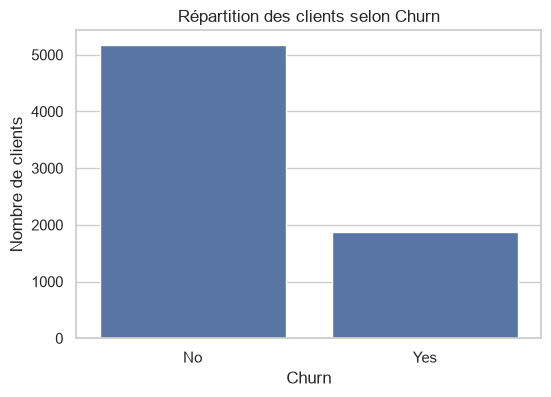

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=df["Churn"].value_counts().index)
plt.title("Répartition des clients selon Churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.show()

## 5. Valeurs manquantes

In [15]:
missing = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (df.isna().mean() * 100).round(2)
})
display(missing.sort_values("Valeurs manquantes", ascending=False))

,Valeurs manquantes,Pourcentage (%)
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


## 6. Vérifier les doublons

In [16]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

if "customerID" in df.columns:
    print("Nombre de customerID dupliqués :", df["customerID"].duplicated().sum())

Nombre de lignes dupliquées : 0
Nombre de customerID dupliqués : 0


## 7. Vérifier les types des colonnes
Dans ce dataset, `TotalCharges` peut être importée comme texte à cause de chaînes vides ou d'espaces. Nous vérifions cela avant de convertir.

In [17]:
display(df.dtypes.to_frame("Type actuel"))

,Type actuel
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [18]:
if "TotalCharges" in df.columns:
    print("Type avant conversion :", df["TotalCharges"].dtype)
    print("Chaînes vides / espaces :",
          df["TotalCharges"].astype(str).str.strip().eq("").sum())

    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].astype(str).str.strip(),
        errors="coerce"
    )
    print("Type après conversion :", df["TotalCharges"].dtype)
    print("Valeurs manquantes après conversion :", df["TotalCharges"].isna().sum())

Type avant conversion : str
Chaînes vides / espaces : 11
Type après conversion : float64
Valeurs manquantes après conversion : 11


## 8. Examiner les variables numériques

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Variables numériques :", numeric_cols)

if numeric_cols:
    display(df[numeric_cols].describe().T)

Variables numériques : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


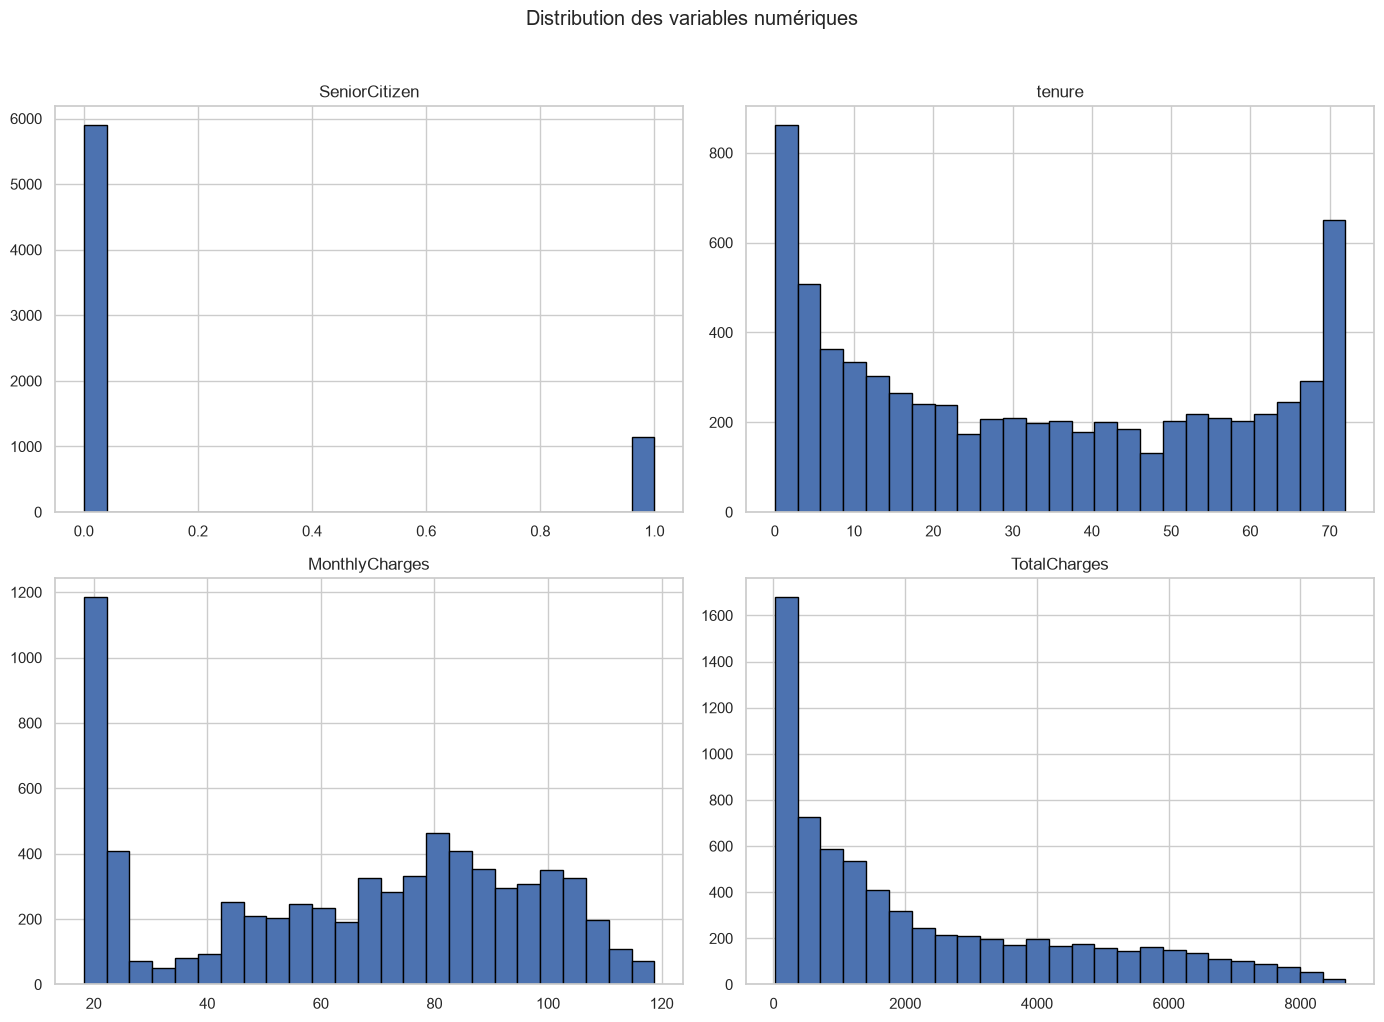

In [20]:
if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=25, edgecolor="black")
    plt.suptitle("Distribution des variables numériques", y=1.02)
    plt.tight_layout()
    plt.show()

## 9. Explorer les variables catégorielles

In [21]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Variables catégorielles :", categorical_cols)

for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).head(15).to_frame("Nombre"))

Variables catégorielles : ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

--- customerID ---


C:\Users\Octinz\AppData\Local\Temp\ipykernel_22004\1930928061.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


,Nombre
customerID,
7590-VHVEG,1
5575-GNVDE,1
3668-QPYBK,1
7795-CFOCW,1
9237-HQITU,1
9305-CDSKC,1
1452-KIOVK,1
6713-OKOMC,1
7892-POOKP,1



--- gender ---


,Nombre
gender,
Male,3555
Female,3488



--- Partner ---


... (25 outputs left out)


--- PaymentMethod ---


,Nombre
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522



--- Churn ---


,Nombre
Churn,
No,5174
Yes,1869


## 10. Relation entre les variables et Churn

In [22]:
# Comparaison des moyennes numériques selon Churn
if "Churn" in df.columns and numeric_cols:
    display(df.groupby("Churn")[numeric_cols].mean(numeric_only=True).T)

Churn,No,Yes
SeniorCitizen,0.128721,0.254682
tenure,37.569965,17.979133
MonthlyCharges,61.265124,74.441332
TotalCharges,2555.344141,1531.796094


In [23]:
# Taux de churn pour quelques variables catégorielles
candidate_cats = [
    col for col in ["Contract", "InternetService", "PaymentMethod",
                    "PaperlessBilling", "SeniorCitizen", "Partner",
                    "Dependents", "TechSupport"]
    if col in df.columns
]

for col in candidate_cats:
    rate = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    if "Yes" in rate.columns:
        display(rate[["Yes"]].rename(columns={"Yes": "Taux de Churn (%)"}).round(2)
                .sort_values("Taux de Churn (%)", ascending=False)
                .style.format("{:.2f}%")
                .set_caption(f"Taux de Churn selon {col}"))

Churn,Taux de Churn (%)
Contract,
Month-to-month,42.71%
One year,11.27%
Two year,2.83%


Churn,Taux de Churn (%)
InternetService,
Fiber optic,41.89%
DSL,18.96%
No,7.40%


Churn,Taux de Churn (%)
PaymentMethod,
Electronic check,45.29%
Mailed check,19.11%
Bank transfer (automatic),16.71%
Credit card (automatic),15.24%


Churn,Taux de Churn (%)
PaperlessBilling,
Yes,33.57%
No,16.33%


Churn,Taux de Churn (%)
SeniorCitizen,
1,41.68%
0,23.61%


Churn,Taux de Churn (%)
Partner,
No,32.96%
Yes,19.66%


Churn,Taux de Churn (%)
Dependents,
No,31.28%
Yes,15.45%


Churn,Taux de Churn (%)
TechSupport,
No,41.64%
Yes,15.17%
No internet service,7.40%


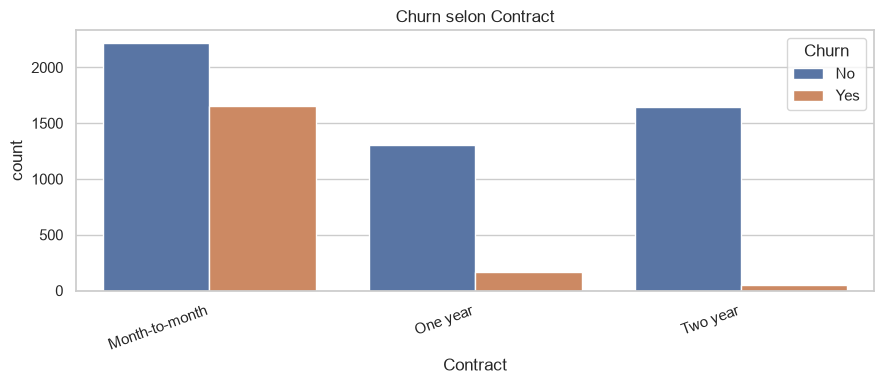

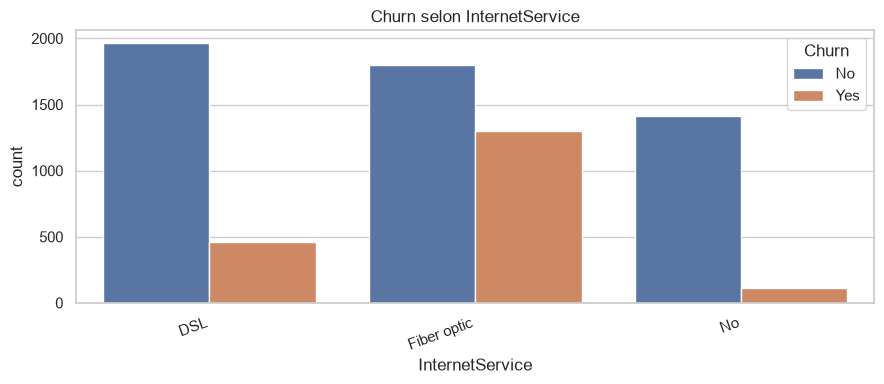

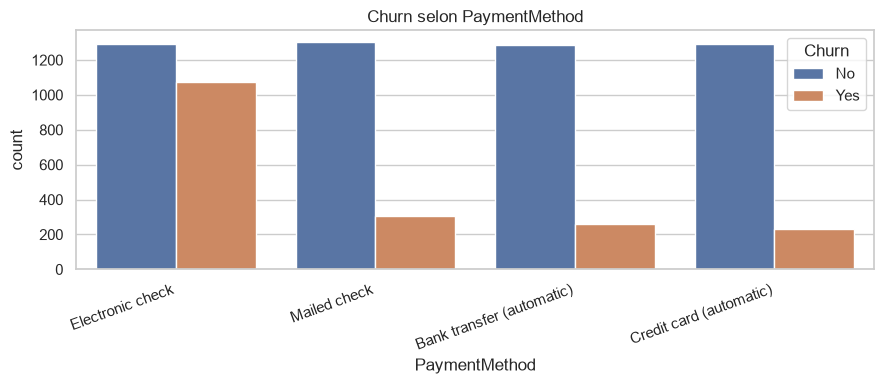

In [24]:
# Visualiser quelques relations importantes si les colonnes existent
for col in ["Contract", "InternetService", "PaymentMethod"]:
    if col in df.columns and "Churn" in df.columns:
        plt.figure(figsize=(9, 4))
        sns.countplot(data=df, x=col, hue="Churn")
        plt.title(f"Churn selon {col}")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()
        plt.show()

## 11. Corrélation entre variables numériques

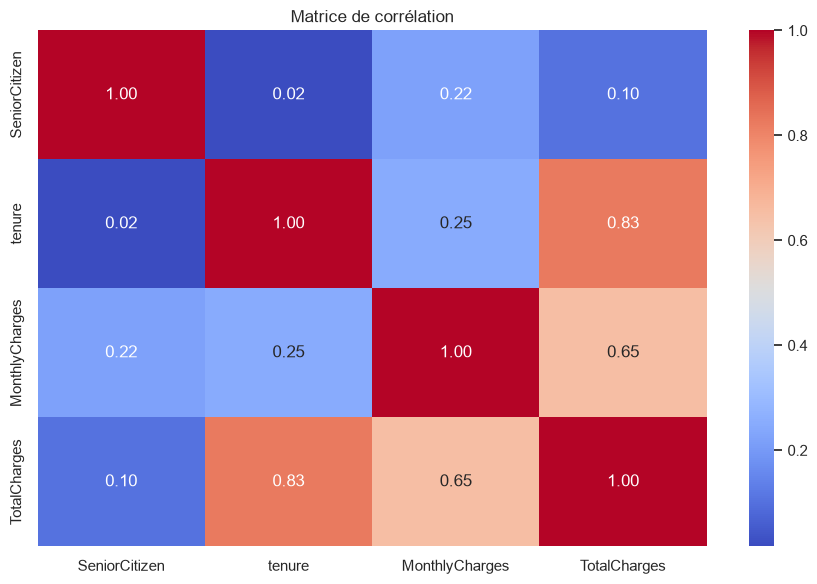

In [25]:
if len(numeric_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Matrice de corrélation")
    plt.tight_layout()
    plt.show()
else:
    print("Pas assez de variables numériques pour calculer une corrélation.")

## 12. Première préparation des données (copie de travail)
Nous créons une copie pour ne pas modifier le dataset brut. Ici, nous :
- supprimons les doublons exacts éventuels ;
- retirons les espaces autour des valeurs textuelles ;
- convertissons `TotalCharges` en numérique (déjà fait plus haut dans `df`).

**Attention :** nous ne supprimons pas automatiquement les lignes avec `TotalCharges` manquant. Il faut d'abord examiner ces lignes et décider d'une stratégie avec l'équipe.

In [26]:
df_clean = df.copy()

# Nettoyer les espaces dans les colonnes textuelles
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].str.strip()

# Supprimer les doublons exacts éventuels
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
after = len(df_clean)

print("Lignes avant :", before)
print("Doublons supprimés :", before - after)
print("Lignes après :", after)

# Examiner les lignes où TotalCharges est manquant, si applicable
if "TotalCharges" in df_clean.columns:
    display(df_clean[df_clean["TotalCharges"].isna()].head(10))

Lignes avant : 7043
Doublons supprimés : 0
Lignes après : 7043


C:\Users\Octinz\AppData\Local\Temp\ipykernel_22004\2695798742.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include=["object"]).columns:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


## 13. Exporter le dataset de travail

In [27]:
OUTPUT_PATH = PROCESSED_DIR / "telco_churn_exploration.csv"
df_clean.to_csv(OUTPUT_PATH, index=False)

print("Dataset exporté vers :", OUTPUT_PATH)
print("Taille du dataset exporté :", df_clean.shape)

Dataset exporté vers : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed\telco_churn_exploration.csv
Taille du dataset exporté : (7043, 21)


## 14. Résumé automatique des constats
Complète ensuite ce résumé dans le rapport du projet avec les résultats affichés dans le notebook.

In [29]:
print("===== RÉSUMÉ DU DATASET =====")
print(f"Nombre de lignes : {df_clean.shape[0]}")
print(f"Nombre de colonnes : {df_clean.shape[1]}")
print(f"Nombre de doublons restants : {df_clean.duplicated().sum()}")
print(f"Nombre total de valeurs manquantes : {df_clean.isna().sum().sum()}")

if "Churn" in df_clean.columns:
    print("\nDistribution de Churn (%) :")
    print((df_clean["Churn"].value_counts(normalize=True) * 100).round(2))

print("\nNotebook terminé : Data Understanding & EDA.")

===== RÉSUMÉ DU DATASET =====
Nombre de lignes : 7043
Nombre de colonnes : 21
Nombre de doublons restants : 0
Nombre total de valeurs manquantes : 11

Distribution de Churn (%) :
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Notebook terminé : Data Understanding & EDA.


## 15. Questions à discuter en équipe
1. La cible `Churn` est-elle équilibrée ou déséquilibrée ?
2. Quelles variables semblent liées au départ des clients ?
3. Pourquoi `customerID` ne doit généralement pas être utilisé comme variable prédictive ?
4. Quelle stratégie choisir pour les valeurs manquantes de `TotalCharges` ?
5. Quelles transformations seront nécessaires avant l'entraînement (encodage, scaling, séparation train/test) ?

**Prochaine étape :** construire un pipeline de preprocessing reproductible, puis comparer plusieurs modèles de classification.

In [30]:
# Identifier les colonnes avec des valeurs manquantes
missing_cols = df_clean.isnull().sum()

print("Colonnes avec valeurs manquantes :")
print(missing_cols[missing_cols > 0])

# Afficher les lignes concernées
display(df_clean[df_clean.isnull().any(axis=1)])

Colonnes avec valeurs manquantes :
TotalCharges    11
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [31]:
missing_rows = df_clean[df_clean["TotalCharges"].isna()]

print("Nombre de lignes :", len(missing_rows))

print("\nValeurs de tenure :")
print(missing_rows["tenure"].value_counts(dropna=False))

display(
    missing_rows[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

Nombre de lignes : 11

Valeurs de tenure :
tenure
0    11
Name: count, dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [32]:
# Remplacer les 11 valeurs manquantes par 0
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Vérifier le résultat
print("Valeurs manquantes restantes :")
print(df_clean.isnull().sum().sum())

print("\nNombre de clients avec TotalCharges = 0 :")
print((df_clean["TotalCharges"] == 0).sum())

Valeurs manquantes restantes :
0

Nombre de clients avec TotalCharges = 0 :
11


In [33]:
OUTPUT_PATH = PROCESSED_DIR / "telco_churn_clean.csv"

df_clean.to_csv(OUTPUT_PATH, index=False)

print("Dataset sauvegardé :", OUTPUT_PATH)

Dataset sauvegardé : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed\telco_churn_clean.csv
